# Project overview
- Research Question: Which statistical learning models provide stronger next day electricty usage prediction than using the same weekday one day earlier?
- Dataset used: https://github.com/buds-lab/building-data-genome-project-2
    - Contains sensor logs, weather data, and meta data for 1636 buildings from 2016 through 2017

# Sections
- Exploratory Data Analysis
- Data Preprocessing
- Model Selection and Implementation
- Model Evaluation
- Report

Importing libraries and loading data into dataframes

In [145]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

In [146]:
metadata = pd.read_csv("C:/Users/jacks/OneDrive/Desktop/Statistical Learning Final Project/metadata.txt")
electricity = pd.read_csv("C:/Users/jacks/OneDrive/Desktop/Statistical Learning Final Project/electricity.txt", parse_dates=["timestamp"])
weather = pd.read_csv("C:/Users/jacks/OneDrive/Desktop/Statistical Learning Final Project/weather.txt", parse_dates=["timestamp"])

# Exploratory Data Analysis

### - Begin by checking the shape of the data files and which building have complete sensor logs

In [147]:
office_ids = metadata.loc[
    metadata["primaryspaceusage"].eq("Office")
    & metadata["building_id"].isin(electricity.columns),
    "building_id"
].tolist()

print("Electricity shape:", electricity.shape)
print("Metadata shape:", metadata.shape)
print("Weather shape:", weather.shape)
print("Office buildings with electricity:", len(office_ids))

Electricity shape: (17544, 1579)
Metadata shape: (1636, 32)
Weather shape: (331166, 10)
Office buildings with electricity: 296


### - Check how many buildings have complete sensor logs in 2016 to be used in modeling

In [148]:
office_hourly = (
    electricity[["timestamp"] + office_ids]
    .set_index("timestamp")
    .sort_index()
)

# Keep only finite, positive readings.
office_hourly = office_hourly.where(
    office_hourly.gt(0) & np.isfinite(office_hourly)
)

# Preserve the complete hourly calendar.
office_hourly = office_hourly.reindex(
    pd.date_range(
        "2016-01-01", "2017-12-31 23:00:00", freq="h"
    )
)
office_hourly.index.name = "timestamp"

# Incomplete daily totals remain NaN.
daily_electricity = office_hourly.resample("D").sum(min_count=24)

# Rank using 2016 only.
valid_days_2016 = (
    daily_electricity.loc["2016"]
    .notna()
    .sum()
    .sort_values(ascending=False)
)

# Approximately 50: use the 49 buildings complete throughout 2016.
selected_ids = valid_days_2016[
    valid_days_2016.eq(366)
].index.tolist()

daily_selected = daily_electricity[selected_ids].copy()

print("Selected buildings:", len(selected_ids))
print("Daily table shape:", daily_selected.shape)
print(
    "Missing selected building-days in 2016:",
    daily_selected.loc["2016"].isna().sum().sum()
)

Selected buildings: 49
Daily table shape: (731, 49)
Missing selected building-days in 2016: 0


### - Get create plots and summary statistics for the 49 buildings with complete sensor logs during 2016

Building mean daily consumption (kWh):


count       49.0
mean      3152.1
std       3291.1
min        364.9
25%       1014.3
50%       1869.6
75%       3529.3
max      16309.6
dtype: float64

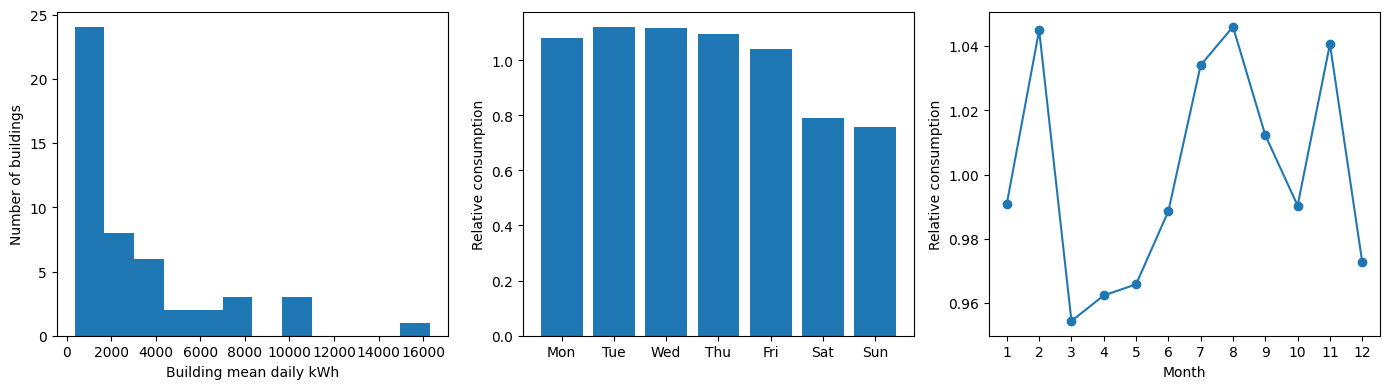

In [149]:
daily_2016 = daily_selected.loc["2016"]

print("Building mean daily consumption (kWh):")
display(daily_2016.mean().describe().round(1))

# Normalize for plotting so each building contributes equally.
relative_usage = daily_2016.div(daily_2016.mean())

weekday_pattern = (
    relative_usage.groupby(relative_usage.index.dayofweek)
    .mean()
    .mean(axis=1)
)

monthly_pattern = (
    relative_usage.groupby(relative_usage.index.month)
    .mean()
    .mean(axis=1)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(daily_2016.mean(), bins=12)
axes[0].set_xlabel("Building mean daily kWh")
axes[0].set_ylabel("Number of buildings")

axes[1].bar(range(7), weekday_pattern.values)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_ylabel("Relative consumption")

axes[2].plot(monthly_pattern.index, monthly_pattern.values, marker="o")
axes[2].set_xticks(range(1, 13))
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Relative consumption")

plt.tight_layout()
plt.show()

### - These plots show a right-tailed distributions where a few buildings consume much more energy than the average building. 
### - Energy consumption also seems to be lower during the weekends and the spring months.

In [150]:
selected_metadata = metadata.loc[
    metadata["building_id"].isin(selected_ids)
].copy()

selected_sites = selected_metadata["site_id"].unique()

weather_2016 = weather.loc[
    weather["site_id"].isin(selected_sites)
    & weather["timestamp"].dt.year.eq(2016)
]

weather_cols = ["airTemperature", "dewTemperature", "windSpeed"]

display(
    weather_2016[weather_cols].agg(["min", "max"])
)

print("Missing measurements within existing rows (%):")
display(
    weather_2016[weather_cols].isna().mean().mul(100).round(2)
)

print("Absent hourly rows by site:")
display(
    8784 - weather_2016.groupby("site_id").size()
)

,airTemperature,dewTemperature,windSpeed
min,-28.9,-31.7,0.0
max,35.6,25.0,19.0


Missing measurements within existing rows (%):


airTemperature    0.01
dewTemperature    0.01
windSpeed         0.01
dtype: float64

Absent hourly rows by site:


site_id
Hog       1
Lamb     29
Robin    21
Shrew    21
Wolf     29
dtype: int64

# Data Preprocessing
 - Target Variable
    - Selected Day's electricty consumptions (kWh), continuous
 - Predictor Features
    - 1 day consumption lag: the electricty consumption of the previous day (kWh), continuous
    - 7 day consumption lag: the electricity consumption of the same day of the previous week (kWh), continuous
    - Trailing 7 day mean: the mean electricty consumption of the previous 7 days (kwH), continuous
    - Trailing 28 day mean: the mean electricty consumption of the previous 28 days (kwH), continuous
    - Previous day weather: minimum air temperature, maximum air temperature, mean air temperature, dew point, and wind speeds, continuous
    - Weekday: the weekday of the target date (Monday, Tuesday, etc), categorical
    - Month: the month of the target, date categorical

### - Creating the 1 day lag feature

In [151]:
lag_1_day = daily_selected.shift(1)

# Inspect one building.
building = selected_ids[0]

check = pd.DataFrame({
    "target_kwh": daily_selected[building],
    "lag_1_day_kwh": lag_1_day[building]
})

print("Building:", building)
display(check.head(8))

# Verify one example explicitly.
assert (
    lag_1_day.loc["2016-01-02", building]
    == daily_selected.loc["2016-01-01", building]
)

Building: Hog_office_Miriam


,target_kwh,lag_1_day_kwh
timestamp,,
2016-01-01,362.010,NaN
2016-01-02,364.973,362.010
2016-01-03,380.753,364.973
2016-01-04,570.098,380.753
2016-01-05,571.482,570.098
2016-01-06,562.404,571.482
2016-01-07,564.175,562.404
2016-01-08,565.443,564.175


### - Creating the 7 day lag feature

In [152]:
lag_7_day = daily_selected.shift(7)

check = pd.DataFrame({
    "target_kwh": daily_selected[building],
    "lag_1_day_kwh": lag_1_day[building],
    "lag_7_day_kwh": lag_7_day[building]
})

display(check.head(10))

assert (
    lag_7_day.loc["2016-01-08", building]
    == daily_selected.loc["2016-01-01", building]
)

,target_kwh,lag_1_day_kwh,lag_7_day_kwh
timestamp,,,
2016-01-01,362.010,NaN,NaN
2016-01-02,364.973,362.010,NaN
2016-01-03,380.753,364.973,NaN
2016-01-04,570.098,380.753,NaN
2016-01-05,571.482,570.098,NaN
2016-01-06,562.404,571.482,NaN
2016-01-07,564.175,562.404,NaN
2016-01-08,565.443,564.175,362.010
2016-01-09,475.641,565.443,364.973


### - Creating the 7 and 28 day trailing features

In [153]:
trailing_7_day = lag_1_day.rolling(
    window=7, min_periods=7
).mean()

trailing_28_day = lag_1_day.rolling(
    window=28, min_periods=28
).mean()

check = pd.DataFrame({
    "target_kwh": daily_selected[building],
    "trailing_7_day_kwh": trailing_7_day[building],
    "trailing_28_day_kwh": trailing_28_day[building]
})

display(check.head(10))
display(check.loc["2016-01-27":"2016-01-30"])

# January 8's mean must use January 1–7.
assert np.isclose(
    trailing_7_day.loc["2016-01-08", building],
    daily_selected.loc["2016-01-01":"2016-01-07", building].mean()
)

# January 29's mean must use January 1–28.
assert np.isclose(
    trailing_28_day.loc["2016-01-29", building],
    daily_selected.loc["2016-01-01":"2016-01-28", building].mean()
)

,target_kwh,trailing_7_day_kwh,trailing_28_day_kwh
timestamp,,,
2016-01-01,362.010,NaN,NaN
2016-01-02,364.973,NaN,NaN
2016-01-03,380.753,NaN,NaN
2016-01-04,570.098,NaN,NaN
2016-01-05,571.482,NaN,NaN
2016-01-06,562.404,NaN,NaN
2016-01-07,564.175,NaN,NaN
2016-01-08,565.443,482.270714,NaN
2016-01-09,475.641,511.332571,NaN


,target_kwh,trailing_7_day_kwh,trailing_28_day_kwh
timestamp,,,
2016-01-27,601.435,557.909714,NaN
2016-01-28,604.078,557.734571,NaN
2016-01-29,594.431,555.821857,533.000429
2016-01-30,468.452,557.108000,541.301179


### - Creating the weekday and month features

In [154]:
calendar_features = pd.DataFrame(
    index=daily_selected.index
)

# Monday = 0, Sunday = 6; January = 1, December = 12.
calendar_features["day_of_week"] = (
    calendar_features.index.dayofweek.astype(str)
)

calendar_features["month"] = (
    calendar_features.index.month.astype(str)
)

display(calendar_features.head(8))

,day_of_week,month
timestamp,,
2016-01-01,4,1
2016-01-02,5,1
2016-01-03,6,1
2016-01-04,0,1
2016-01-05,1,1
2016-01-06,2,1
2016-01-07,3,1
2016-01-08,4,1


### -Create the weather readings features

In [155]:
weather_selected = weather.loc[
    weather["site_id"].isin(selected_sites)
].copy()

weather_daily = (
    weather_selected
    .groupby([
        "site_id",
        pd.Grouper(key="timestamp", freq="D")
    ])
    .agg(
        temp_mean=("airTemperature", "mean"),
        temp_min=("airTemperature", "min"),
        temp_max=("airTemperature", "max"),
        dew_mean=("dewTemperature", "mean"),
        wind_mean=("windSpeed", "mean"),
        temp_count=("airTemperature", "count"),
        dew_count=("dewTemperature", "count"),
        wind_count=("windSpeed", "count")
    )
)

# Preserve every calendar day for every selected site.
weather_index = pd.MultiIndex.from_product(
    [selected_sites, daily_selected.index],
    names=["site_id", "timestamp"]
)

weather_daily = weather_daily.reindex(weather_index).sort_index()

# Mask each summary using its own variable's coverage.
weather_daily.loc[
    weather_daily["temp_count"].ne(24),
    ["temp_mean", "temp_min", "temp_max"]
] = np.nan

weather_daily.loc[
    weather_daily["dew_count"].ne(24), "dew_mean"
] = np.nan

weather_daily.loc[
    weather_daily["wind_count"].ne(24), "wind_mean"
] = np.nan

weather_daily = weather_daily[
    ["temp_mean", "temp_min", "temp_max", "dew_mean", "wind_mean"]
]

display(weather_daily.loc["Hog"].head())

,temp_mean,temp_min,temp_max,dew_mean,wind_mean
timestamp,,,,,
2016-01-01,-5.583333,-9.4,-1.1,-9.741667,4.758333
2016-01-02,-5.462500,-10.0,-0.6,-9.808333,4.262500
2016-01-03,-3.291667,-6.1,-2.2,-7.512500,4.800000
2016-01-04,-7.783333,-12.2,-3.3,-10.133333,3.200000
2016-01-05,-3.820833,-6.7,0.0,-7.933333,5.512500


### - Shifting the weather so that previous days weather can be used as a feature

In [156]:
previous_day_weather = (
    weather_daily
    .groupby(level="site_id")
    .shift(1)
    .add_prefix("prev_")
)

display(previous_day_weather.loc["Hog"].head())

# Verify January 2 uses January 1's weather.
assert np.allclose(
    previous_day_weather.loc[("Hog", "2016-01-02")].to_numpy(),
    weather_daily.loc[("Hog", "2016-01-01")].to_numpy(),
    equal_nan=True
)

,prev_temp_mean,prev_temp_min,prev_temp_max,prev_dew_mean,prev_wind_mean
timestamp,,,,,
2016-01-01,NaN,NaN,NaN,NaN,NaN
2016-01-02,-5.583333,-9.4,-1.1,-9.741667,4.758333
2016-01-03,-5.462500,-10.0,-0.6,-9.808333,4.262500
2016-01-04,-3.291667,-6.1,-2.2,-7.512500,4.800000
2016-01-05,-7.783333,-12.2,-3.3,-10.133333,3.200000


### - Merging the created features to their desired rows for model training.
- Each row will contain a building's energy consumption on a target data and the previously described prediction features.

In [157]:
# Convert the wide building tables to matching building-day rows.
def to_long(table, value_name):
    return (
        table.rename_axis("timestamp")
        .reset_index()
        .melt(
            id_vars="timestamp",
            var_name="building_id",
            value_name=value_name
        )
    )

model_data = to_long(daily_selected, "target_kwh")

consumption_features = {
    "lag_1_day_kwh": lag_1_day,
    "lag_7_day_kwh": lag_7_day,
    "trailing_7_day_kwh": trailing_7_day,
    "trailing_28_day_kwh": trailing_28_day
}

for name, table in consumption_features.items():
    model_data = model_data.merge(
        to_long(table, name),
        on=["timestamp", "building_id"],
        how="left",
        validate="one_to_one"
    )

model_data = model_data.merge(
    calendar_features.reset_index(),
    on="timestamp",
    how="left",
    validate="many_to_one"
)

model_data = model_data.merge(
    selected_metadata[["building_id", "site_id"]],
    on="building_id",
    how="left",
    validate="many_to_one"
)

model_data = model_data.merge(
    previous_day_weather.reset_index(),
    on=["site_id", "timestamp"],
    how="left",
    validate="many_to_one"
)

model_data = model_data.sort_values(
    ["timestamp", "building_id"]
).reset_index(drop=True)

print("Shape:", model_data.shape)
print(
    "Duplicate building-days:",
    model_data.duplicated(["timestamp", "building_id"]).sum()
)

display(
    model_data.loc[
        model_data["building_id"].eq(building)
        & model_data["timestamp"].between("2016-01-29", "2016-01-31")
    ]
)

Shape: (35819, 15)
Duplicate building-days: 0


,timestamp,building_id,target_kwh,lag_1_day_kwh,lag_7_day_kwh,trailing_7_day_kwh,trailing_28_day_kwh,day_of_week,month,site_id,prev_temp_mean,prev_temp_min,prev_temp_max,prev_dew_mean,prev_wind_mean
1386,2016-01-29,Hog_office_Miriam,594.431,604.078,585.428,555.821857,533.000429,4,1,Hog,-0.412500,-6.1,2.8,-5.270833,5.666667
1435,2016-01-30,Hog_office_Miriam,468.452,594.431,462.512,557.108000,541.301179,5,1,Hog,-3.100000,-7.2,0.6,-6.845833,4.595833
1484,2016-01-31,Hog_office_Miriam,465.008,468.452,459.359,557.956571,544.996857,6,1,Hog,2.066667,-0.6,6.1,-1.604167,2.145833


### - Checking for missing values on the rows.

In [158]:
eligible_data = model_data.loc[
    model_data["target_kwh"].notna()
    & model_data["lag_7_day_kwh"].notna()
].copy()

# Check training-period eligibility without inspecting test outcomes.
training_rows = model_data["timestamp"].dt.year.eq(2016)
eligible_training = eligible_data.loc[
    eligible_data["timestamp"].dt.year.eq(2016)
]

print("2016 building-days:", training_rows.sum())
print("Eligible 2016 building-days:", len(eligible_training))

predictor_cols = [
    "lag_1_day_kwh",
    "lag_7_day_kwh",
    "trailing_7_day_kwh",
    "trailing_28_day_kwh",
    "prev_temp_mean",
    "prev_temp_min",
    "prev_temp_max",
    "prev_dew_mean",
    "prev_wind_mean",
    "day_of_week",
    "month",
    "building_id"
]

print("\nMissing predictors among eligible 2016 rows:")
display(eligible_training[predictor_cols].isna().sum())

2016 building-days: 17934
Eligible 2016 building-days: 17591

Missing predictors among eligible 2016 rows:


lag_1_day_kwh             0
lag_7_day_kwh             0
trailing_7_day_kwh        0
trailing_28_day_kwh    1029
prev_temp_mean          261
prev_temp_min           261
prev_temp_max           261
prev_dew_mean           261
prev_wind_mean          240
day_of_week               0
month                     0
building_id               0
dtype: int64

## Setting Data Folds
- As this data is time dependent, random assignment of training data would be inappropriate.
- Instead I used an expanding training fold technique where the models will be trained on a certain range of data and then evaluated on the next 3 months of readings.
- The ranges are as follows
    - Train: Jan 2016 - Dec 2016, Evaluate: Jan 2017 - Mar 2017
    - Train: Jan 2016 - Mar 2017, Evaluate: Apr 2017 - Jun 2017
    - Train: Jan 2016 - Jun 2017, Evaluate: Jul 2017 - Sep 2017
- The final test set will be the evaluation of the models on Oct 2017 - Dec 2017

### - Creating the training folds as previoulsy described.

In [159]:
# Keep final-test rows outside the development data.
development_data = eligible_data.loc[
    eligible_data["timestamp"].lt("2017-10-01")
].copy().reset_index(drop=True)

fold_boundaries = [
    ("2017-01-01", "2017-04-01"),
    ("2017-04-01", "2017-07-01"),
    ("2017-07-01", "2017-10-01")
]

folds = []
fold_summary = []

for fold_number, (start, end) in enumerate(fold_boundaries, start=1):
    dates = development_data["timestamp"]

    train_idx = np.flatnonzero(dates.lt(start).to_numpy())
    val_idx = np.flatnonzero(
        (dates.ge(start) & dates.lt(end)).to_numpy()
    )

    folds.append((train_idx, val_idx))

    train = development_data.iloc[train_idx]
    validation = development_data.iloc[val_idx]

    assert train["timestamp"].max() < validation["timestamp"].min()
    assert set(validation["building_id"]).issubset(
        set(train["building_id"])
    )

    fold_summary.append({
        "fold": fold_number,
        "train_end": train["timestamp"].max(),
        "validation_start": validation["timestamp"].min(),
        "validation_end": validation["timestamp"].max(),
        "train_rows": len(train),
        "validation_rows": len(validation),
        "validation_buildings": validation["building_id"].nunique()
    })

display(pd.DataFrame(fold_summary))

,fold,train_end,validation_start,validation_end,train_rows,validation_rows,validation_buildings
0,1,2016-12-31,2017-01-01,2017-03-31,17591,4000,49
1,2,2017-03-31,2017-04-01,2017-06-30,21591,3903,43
2,3,2017-06-30,2017-07-01,2017-09-30,25494,3920,43


### - Check the completeness of the folds

In [160]:
availability = []

for fold_number, (start, end) in enumerate(fold_boundaries, start=1):
    quarter = model_data.loc[
        model_data["timestamp"].ge(start)
        & model_data["timestamp"].lt(end)
    ]

    valid_target = quarter["target_kwh"].notna()
    valid_baseline = quarter["lag_7_day_kwh"].notna()

    availability.append({
        "fold": fold_number,
        "possible_rows": len(quarter),
        "missing_target": (~valid_target).sum(),
        "valid_target_missing_baseline": (
            valid_target & ~valid_baseline
        ).sum(),
        "eligible_rows": (valid_target & valid_baseline).sum()
    })

display(pd.DataFrame(availability))

,fold,possible_rows,missing_target,valid_target_missing_baseline,eligible_rows
0,1,4410,401,9,4000
1,2,4459,551,5,3903
2,3,4508,570,18,3920


In [161]:
numeric_cols = predictor_cols[:9]
categorical_cols = ["day_of_week", "month", "building_id"]

def make_preprocessor(scale=True):
    numeric_steps = [
        ("impute", SimpleImputer(strategy="median"))
    ]

    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_cols),
        (
            "missing",
            MissingIndicator(features="all"),
            numeric_cols
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ])

In [162]:
train_idx, val_idx = folds[0]

preprocessor_check = make_preprocessor()

X_train_check = preprocessor_check.fit_transform(
    development_data.iloc[train_idx][predictor_cols]
)

X_val_check = preprocessor_check.transform(
    development_data.iloc[val_idx][predictor_cols]
)

print("Training shape:", X_train_check.shape)
print("Validation shape:", X_val_check.shape)
print("All training values finite:", np.isfinite(X_train_check).all())
print("All validation values finite:", np.isfinite(X_val_check).all())

Training shape: (17591, 83)
Validation shape: (4000, 83)
All training values finite: True
All validation values finite: True


# Model Selection
 - Baseline: The baseline model will simply use the previous same weekdays energy consumption as the prediction. All of our selected models will be compared to this as the benchmark to beat.
 
 - Ordinary Least Squares (OLS): this will provide a simple linear model showing the effect of each predictor on the model. It will provide useful reference into the contribution of each predictor, but will likely prove to be inadequate as it will be subject to the multicolinearity of many of our predictor features and incapable of capturing non linear relationships within the data.

 - Ridge Regression: this will also create a linear model to represent the relationship between the prediction features and the target variable. However, a regularization vaariable will be used to shrink feature coefficients and deal with some of the multicolinearity in the data. Coefficients to be tested are: 0.1, 1, 10, 100, 1000, and 10000. This model will be unable to capture possible nonlinear relationships within the data.

 - Regression Tree: this model will partition predictor space into a tree like structure and predict the mean training response within each leaf. This technique will allow for it to be capable of representing nonlinear relationships, though it will not be able to explicitly describe the relationships forms. Depths of 3, 5, and 10 will be tested with minimum leaf sizes of 10, 50, and 100. A possible weakness of this approach is an over sensitivity to the training data.

# Model Evaluation
- The models loss was evaluated under two measures
    - Root mean squared error (RMSE): will place greater weight on large errors and serve as the secondary evaluation metric
    - Mean average error (MAE): expresses the typical forecast error and will serve as the primary evaluation metric

## - Set the baseline model

In [163]:
baseline_results = []

for fold_number, (_, val_idx) in enumerate(folds, start=1):
    validation = development_data.iloc[val_idx]

    actual = validation["target_kwh"]
    predicted = validation["lag_7_day_kwh"]

    baseline_results.append({
        "fold": fold_number,
        "MAE_kwh": mean_absolute_error(actual, predicted),
        "RMSE_kwh": np.sqrt(mean_squared_error(actual, predicted)),
        "rows": len(validation)
    })

display(pd.DataFrame(baseline_results).round(2))

,fold,MAE_kwh,RMSE_kwh,rows
0,1,245.38,536.12,4000
1,2,568.61,2135.10,3903
2,3,859.90,3375.53,3920


## - Set and train the OLS model

In [164]:
ols_results = []
ols_validation_predictions = []

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    train = development_data.iloc[train_idx]
    validation = development_data.iloc[val_idx]

    ols = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", LinearRegression())
    ])

    ols.fit(train[predictor_cols], train["target_kwh"])
    predicted = ols.predict(validation[predictor_cols])

    baseline_mae = baseline_results[fold_number - 1]["MAE_kwh"]
    ols_mae = mean_absolute_error(
        validation["target_kwh"], predicted
    )

    ols_results.append({
        "fold": fold_number,
        "MAE_kwh": ols_mae,
        "RMSE_kwh": np.sqrt(
            mean_squared_error(validation["target_kwh"], predicted)
        ),
        "MAE_improvement_pct": (
            100 * (baseline_mae - ols_mae) / baseline_mae
        )
    })
    
        # Save predictions for later per-building comparisons.
    fold_predictions = validation[
        ["timestamp", "building_id", "target_kwh", "lag_7_day_kwh"]
    ].copy()

    fold_predictions["ols_prediction"] = predicted
    fold_predictions["fold"] = fold_number
    ols_validation_predictions.append(fold_predictions)

display(pd.DataFrame(ols_results).round(2))

,fold,MAE_kwh,RMSE_kwh,MAE_improvement_pct
0,1,277.96,446.35,-13.28
1,2,447.22,1215.18,21.35
2,3,621.26,1899.92,27.75


## - Set and train the Ridge Regression model

In [165]:
ridge_results = []

for alpha in [0.1, 1, 10, 100, 1000, 10000]:
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
        train = development_data.iloc[train_idx]
        validation = development_data.iloc[val_idx]

        ridge = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", Ridge(alpha=alpha))
        ])

        ridge.fit(train[predictor_cols], train["target_kwh"])
        predicted = ridge.predict(validation[predictor_cols])

        ridge_results.append({
            "alpha": alpha,
            "fold": fold_number,
            "MAE_kwh": mean_absolute_error(
                validation["target_kwh"], predicted
            ),
            "MSE": mean_squared_error(
                validation["target_kwh"], predicted
            ),
            "rows": len(validation)
        })

ridge_scores = pd.DataFrame(ridge_results)

ridge_summary = pd.DataFrame([
    {
        "alpha": alpha,
        "MAE_kwh": np.average(group["MAE_kwh"], weights=group["rows"]),
        "RMSE_kwh": np.sqrt(
            np.average(group["MSE"], weights=group["rows"])
        )
    }
    for alpha, group in ridge_scores.groupby("alpha")
]).sort_values("MAE_kwh")

display(ridge_summary.round(2))

,alpha,MAE_kwh,RMSE_kwh
3,100.0,437.39,1328.71
4,1000.0,445.50,1378.47
2,10.0,445.67,1323.79
1,1.0,447.43,1323.53
0,0.1,447.64,1323.52
5,10000.0,615.11,1586.20


## - Set and train the Regression Tree model

In [166]:
tree_results = []

for max_depth in [3, 5, 10]:
    for min_samples_leaf in [10, 50, 100]:
        for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
            train = development_data.iloc[train_idx]
            validation = development_data.iloc[val_idx]

            tree = Pipeline([
                ("preprocess", make_preprocessor(scale=False)),
                ("model", DecisionTreeRegressor(
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    random_state=42
                ))
            ])

            tree.fit(train[predictor_cols], train["target_kwh"])
            predicted = tree.predict(validation[predictor_cols])

            tree_results.append({
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "fold": fold_number,
                "MAE_kwh": mean_absolute_error(
                    validation["target_kwh"], predicted
                ),
                "MSE": mean_squared_error(
                    validation["target_kwh"], predicted
                ),
                "rows": len(validation)
            })

tree_scores = pd.DataFrame(tree_results)

tree_summary = pd.DataFrame([
    {
        "max_depth": depth,
        "min_samples_leaf": leaf_size,
        "MAE_kwh": np.average(group["MAE_kwh"], weights=group["rows"]),
        "RMSE_kwh": np.sqrt(
            np.average(group["MSE"], weights=group["rows"])
        )
    }
    for (depth, leaf_size), group in tree_scores.groupby(
        ["max_depth", "min_samples_leaf"]
    )
]).sort_values("MAE_kwh")

display(tree_summary.round(2))

,max_depth,min_samples_leaf,MAE_kwh,RMSE_kwh
7,10,50,424.44,1460.51
6,10,10,432.64,1484.21
8,10,100,440.78,1462.03
3,5,10,499.79,1464.60
4,5,50,501.89,1485.62
5,5,100,505.92,1481.04
0,3,10,700.76,1623.85
2,3,100,700.76,1623.85
1,3,50,700.76,1623.85


## - Create a table to compare the performance of the models

In [167]:
validation_rows = np.array([len(val_idx) for _, val_idx in folds])

comparison = pd.DataFrame([
    {
        "model": "7-day baseline",
        "MAE_kwh": np.average(
            [r["MAE_kwh"] for r in baseline_results],
            weights=validation_rows
        ),
        "RMSE_kwh": np.sqrt(np.average(
            [r["RMSE_kwh"] ** 2 for r in baseline_results],
            weights=validation_rows
        ))
    },
    {
        "model": "OLS",
        "MAE_kwh": np.average(
            [r["MAE_kwh"] for r in ols_results],
            weights=validation_rows
        ),
        "RMSE_kwh": np.sqrt(np.average(
            [r["RMSE_kwh"] ** 2 for r in ols_results],
            weights=validation_rows
        ))
    },
    {
        "model": "Ridge",
        "MAE_kwh": ridge_summary.iloc[0]["MAE_kwh"],
        "RMSE_kwh": ridge_summary.iloc[0]["RMSE_kwh"]
    },
    {
        "model": "Regression tree",
        "MAE_kwh": tree_summary.iloc[0]["MAE_kwh"],
        "RMSE_kwh": tree_summary.iloc[0]["RMSE_kwh"]
    }
]).sort_values("MAE_kwh").reset_index(drop=True)

display(comparison.round(2))

,model,MAE_kwh,RMSE_kwh
0,Regression tree,424.44,1460.51
1,Ridge,437.39,1328.71
2,OLS,447.66,1323.52
3,7-day baseline,555.84,2319.47


## -Final test
- Testing the trained models on the unseen Oct 2017 - Dec 2017 dates

In [168]:
pretest = development_data.copy()

test = eligible_data.loc[
    eligible_data["timestamp"].ge("2017-10-01")
    & eligible_data["timestamp"].lt("2018-01-01")
].copy()

assert pretest["timestamp"].max() < test["timestamp"].min()

final_models = {
    "OLS": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", Ridge(alpha=100))
    ]),
    "Regression tree": Pipeline([
        ("preprocess", make_preprocessor(scale=False)),
        ("model", DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=50,
            random_state=42
        ))
    ])
}

test_predictions = test[
    ["timestamp", "building_id", "target_kwh"]
].copy()

test_predictions["7-day baseline"] = test["lag_7_day_kwh"]

for name, model in final_models.items():
    model.fit(pretest[predictor_cols], pretest["target_kwh"])
    test_predictions[name] = model.predict(test[predictor_cols])

test_results = pd.DataFrame([
    {
        "model": name,
        "MAE_kwh": mean_absolute_error(
            test_predictions["target_kwh"], test_predictions[name]
        ),
        "RMSE_kwh": np.sqrt(mean_squared_error(
            test_predictions["target_kwh"], test_predictions[name]
        ))
    }
    for name in ["7-day baseline"] + list(final_models)
]).sort_values("MAE_kwh").reset_index(drop=True)

print("Pre-test training rows:", len(pretest))
print("Eligible test rows:", len(test))
print("Buildings represented in test:", test["building_id"].nunique())


fitted_tree = final_models["Regression tree"].named_steps["model"]

print("Actual depth:", fitted_tree.get_depth())
print("Number of leaves:", fitted_tree.get_n_leaves())
display(test_results.round(2))

Pre-test training rows: 29414
Eligible test rows: 3859
Buildings represented in test: 43
Actual depth: 10
Number of leaves: 256


,model,MAE_kwh,RMSE_kwh
0,Regression tree,246.72,627.88
1,Ridge,302.72,651.14
2,OLS,317.76,660.23
3,7-day baseline,335.06,1280.52


## Per Building Analysis
- Checking how many of the building predictions on average had lower loss from the models compared to the baseline

In [169]:
per_building_results = []

model_names = ["7-day baseline"] + list(final_models)

for building_id, group in test_predictions.groupby("building_id"):
    baseline_mae = mean_absolute_error(
        group["target_kwh"], group["7-day baseline"]
    )

    for name in model_names:
        mae = mean_absolute_error(group["target_kwh"], group[name])

        per_building_results.append({
            "building_id": building_id,
            "model": name,
            "test_days": len(group),
            "MAE_kwh": mae,
            "RMSE_kwh": np.sqrt(mean_squared_error(
                group["target_kwh"], group[name]
            )),
            "MAE_improvement_pct": (
                100 * (baseline_mae - mae) / baseline_mae
                if baseline_mae > 0 else np.nan
            )
        })

per_building = pd.DataFrame(per_building_results)

building_summary = (
    per_building.loc[per_building["model"].ne("7-day baseline")]
    .groupby("model")
    .agg(
        buildings=("building_id", "nunique"),
        buildings_beating_baseline=(
            "MAE_improvement_pct",
            lambda values: values.gt(0).sum()
        ),
        median_MAE_improvement_pct=("MAE_improvement_pct", "median"),
        mean_building_MAE_kwh=("MAE_kwh", "mean")
    )
)

display(building_summary.round(2))

print("Eligible test days per building:")
display(
    per_building.loc[
        per_building["model"].eq("7-day baseline"), "test_days"
    ].describe()
)

,buildings,buildings_beating_baseline,median_MAE_improvement_pct,mean_building_MAE_kwh
model,,,,
OLS,43,16,-36.77,316.96
Regression tree,43,37,16.40,246.13
Ridge,43,19,-17.11,302.80


Eligible test days per building:


count    43.000000
mean     89.744186
std      12.703755
min       9.000000
25%      92.000000
50%      92.000000
75%      92.000000
max      92.000000
Name: test_days, dtype: float64

## - Plot each models performance vs the baseline predictions
- Points under the line were predictions where the model's loss was less than the baesline's

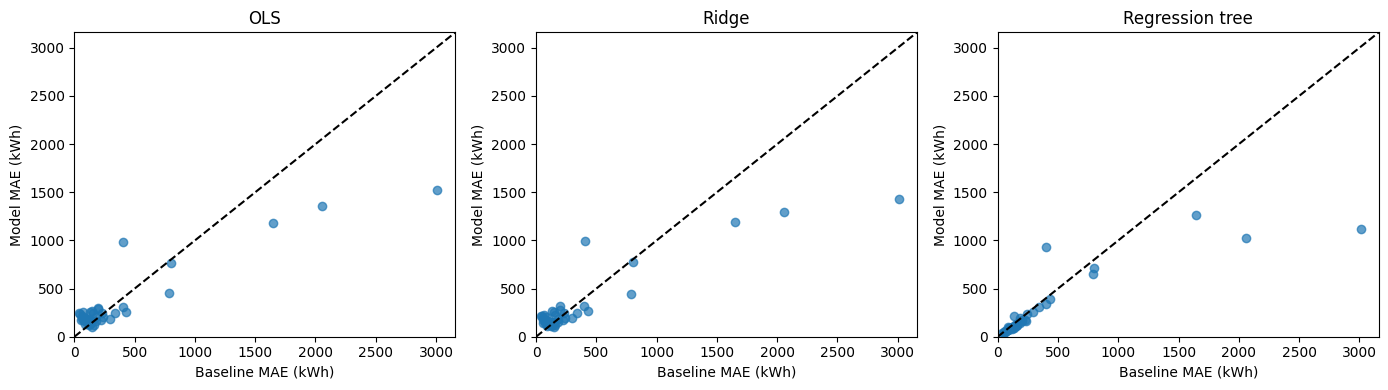

In [170]:
building_mae = per_building.pivot(
    index="building_id",
    columns="model",
    values="MAE_kwh"
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, name in zip(
    axes, ["OLS", "Ridge", "Regression tree"]
):
    baseline = building_mae["7-day baseline"]
    model_mae = building_mae[name]

    limit = max(baseline.max(), model_mae.max()) * 1.05

    ax.scatter(baseline, model_mae, alpha=0.7)
    ax.plot([0, limit], [0, limit], "--", color="black")
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_title(name)
    ax.set_xlabel("Baseline MAE (kWh)")
    ax.set_ylabel("Model MAE (kWh)")

plt.tight_layout()
plt.show()

## -Testing hypothesis that buildings with the largest power consumption skewed the training.

In [171]:
largest_baseline_errors = (
    building_mae["7-day baseline"].nlargest(3).index
)

display(building_mae.loc[largest_baseline_errors].round(2))

diagnostic_results = []

for sample, rows in [
    ("All test buildings", test_predictions),
    (
        "Other 40 buildings",
        test_predictions.loc[
            ~test_predictions["building_id"].isin(largest_baseline_errors)
        ]
    )
]:
    baseline_mae = mean_absolute_error(
        rows["target_kwh"], rows["7-day baseline"]
    )

    for name in model_names:
        mae = mean_absolute_error(rows["target_kwh"], rows[name])

        diagnostic_results.append({
            "sample": sample,
            "model": name,
            "MAE_kwh": mae,
            "MAE_improvement_pct": 100 * (baseline_mae - mae) / baseline_mae
        })

display(pd.DataFrame(diagnostic_results).round(2))

model,7-day baseline,OLS,Regression tree,Ridge
building_id,,,,
Hog_office_Betsy,3010.54,1522.85,1120.38,1431.73
Hog_office_Lavon,2056.39,1359.14,1028.66,1294.24
Hog_office_Garrett,1647.54,1182.30,1268.55,1187.18


,sample,model,MAE_kwh,MAE_improvement_pct
0,All test buildings,7-day baseline,335.06,0.00
1,All test buildings,OLS,317.76,5.16
2,All test buildings,Ridge,302.72,9.65
3,All test buildings,Regression tree,246.72,26.37
4,Other 40 buildings,7-day baseline,192.53,0.00
5,Other 40 buildings,OLS,240.51,-24.92
6,Other 40 buildings,Ridge,228.24,-18.55
7,Other 40 buildings,Regression tree,181.00,5.99


# Report

John Schwarm
Statistical Learning Final Project Write Up

Introduction
	This project will focus on analyzing whether statistical learning methods can provide better prediction of building electricity usage than using a simple prediction technique of using the same weekday of the previous week. This is a useful investigation as it will provide insight into the value of statistical techniques for energy companies in deciding how to partition their resources to certain buildings. The dataset used for this project is the Building Data Genome Project 2 (https://github.com/buds-lab/building-data-genome-project-2) which contains hourly sensor readings, weather data, and meta data information for 1636 buildings from 2016 to 2017. The research question of this project will be; Which statistical learning models provide stronger next day electricity usage prediction than using the same weekday one day earlier?

Exploratory Data Analysis
	In my exploratory analysis of this dataset I wanted to analyze the completeness of the electricity records, completeness of the weather records, and examine other possible features that could carry predictive weight. From the dataset there were a total of 296 buildings with electricity sensor logs, 49 of which were complete in 2016. These buildings were selected as the buildings to be used in the model as data from 2016 would carry a large load in training. Other possible features to be investigated were trends in daily and monthly electricity usage which both showed to be relevant as there were observable decreases in electricity usage during the weekend and the spring season. The plot of average building energy usage also showed a right skewed distribution with a subset of buildings consuming much more electricity than the average.

Data Preprocessing
	For preprocessing the data, the sum of daily power usage (kWh) was used as the target variable. The predictor features were:
   - 1 day consumption lag: the electricity consumption of the previous day (kWh), continuous
    - 7 day consumption lag: the electricity consumption of the same day of the previous week (kWh), continuous
    - Trailing 7 day mean: the mean electricity consumption of the previous 7 days (kwH), continuous
    - Trailing 28 day mean: the mean electricity consumption of the previous 28 days (kwH), continuous
    - Previous day weather: minimum air temperature, maximum air temperature, mean air temperature, dew point, and wind speeds, continuous
    - Weekday: the weekday of the target date (Monday, Tuesday, etc), categorical
    - Month: the month of the target, date categorical
Once the features were created and properly shifted (eg Previous day weather represented the weather of the day before the target variable). They were merged into rows that contained the target variable and all of the predictor features for model training. Training folds were also created using an expanding training fold technique. Since this data was chronologically time dependent, random training set selection would not be appropriate. The folds created were as follows:
- Train: Jan 2016 - Dec 2016, Evaluate: Jan 2017 - Mar 2017
- Train: Jan 2016 - Mar 2017, Evaluate: Apr 2017 - Jun 2017
- Train: Jan 2016 - Jun 2017, Evaluate: Jul 2017 - Sep 2017
- Final Testing Set: Oct 2017- Dec 2017

Model Selection
	There were 4 models assessed in this project; the baseline model of the previous same weekday’s consumption, ordinarily least squares, ridge regression, and regression tree. Here are description of the models used:
 - Baseline: The baseline model will simply use the previous same weekdays energy consumption as the prediction. All of our selected models will be compared to this as the benchmark to beat.
 - Ordinary Least Squares (OLS): this will provide a simple linear model showing the effect of each predictor on the model. It will provide useful reference into the contribution of each predictor, but will likely prove to be inadequate as it will be subject to the multicolinearity of many of our predictor features and incapable of capturing non linear relationships within the data.
 - Ridge Regression: this will also create a linear model to represent the relationship between the prediction features and the target variable. However, a regularization variable will be used to shrink feature coefficients and deal with some of the multicolinearity in the data. Coefficients to be tested are: 0.1, 1, 10, 100, 1000, and 10000. This model will be unable to capture possible nonlinear relationships within the data.
 - Regression Tree: this model will partition predictor space into a tree-like structure and predict the mean training response within each leaf. This technique will allow for it to be capable of representing nonlinear relationships, though it will not be able to explicitly describe the relationships forms. Depths of 3, 5, and 10 will be tested with minimum leaf sizes of 10, 50, and 100. A possible weakness of this approach is an over sensitivity to the training data.
 
Model Evaluation
	Models were evaluated using root mean squared error (RMSE) and mean average error (MAE). MAE was used as the primary evaluation metric as it provides the average error in energy predictions day to day which would be more relevant to the energy forecasting problem.
	Hyper parameters had to be selected for ridge regression and the regression tree models. These were selected by evaluating the different hyperparameters on the training folds before they were exposed to the final training set. The results were as follows
Ridge Regression:

Regularization penalty of 100 selected
Regression tree:

Hyperparameters of max depth of 10 and minimum sample leaves of 50 selected.
	The models were then analyzed against the final test set. 
Results
Here is a chart of all the models and their evaluation metrics:

All models improved on overall MAE and RMSE from the baseline prediction, while this looks good on the surface, further inspection is required. The following chart shows the per building results; how many buildings did the models perform better on average than the baseline model.


These results show that while the OLS and ridge regression models were overall able to have a lower MAE and RMSE than the baseline model this was because of them making less significant mistakes, but they actually show less prediction accuracy than the baseline model on a building by building basis. 
Further investigation showed that the statistical models gained a lot of improvement from building with extremely high electricity consumption and showed more modest gains with the regression tree and actually performance loss in the case of OLS and ridge regression models when tested on the buildings outside of the three highest energy consumers.

Conclusion
	In conclusion the statistical learning models showed an improvement on the previous week baseline by their improvements on MAE. The regression tree in particular performed strongly, showing a 26.7% reduction in MAE compared to the baseline on the testing set while OLS and ridge regression showed more modest improvements of 5.16% and 9.65% respectively. The models did appear to overvalue the largest, most electricity consuming buildings in their training however. When they were removed OLS performed  24.92% worse than the baseline on MAE while ridge regression performed 18.55% worse than the baseline. The regression tree still showed improvement, though it was much more modest at 5.99%. I believe these techniques could show stronger performance and prediction capability if the data was clustered in preprocessing to group buildings more by their relative size and category.
